# A Tour of Regression Models — Energy Forecasting Edition (PJM Hourly Load)

Same lineup: **Linear Regression → Ridge/Lasso/Elastic Net → MLP → Random Forest →
XGBoost → CatBoost → LightGBM**, each tuned via `RandomizedSearchCV` with a compact parameter search, then **ARIMA / SARIMA** fit on the load series itself — the
classical time-series model those lag features are a tabular stand-in for.

**Dataset:** [PJM Hourly Energy Consumption](https://www.kaggle.com/datasets/robikscube/hourly-energy-consumption)
(Kaggle, `robikscube/...`) — real hourly electricity load (megawatts) for PJM
East, a large US regional transmission operator, **2002–2018** (~145,000 hours).

**What's new here vs. the crypto microstructure notebook:** that notebook
predicted volatility *from* a rich set of contemporaneous quote/order-book
features. This dataset has exactly **one column** — a timestamp and a load value —
so the entire feature set has to be *engineered* from the series' own history and
calendar structure: lagged values, rolling statistics, hour-of-day, day-of-week,
month. This is the classic "turn a time series into a tabular ML problem" recipe,
and it's worth seeing in full because it's the same recipe you'd reach for with
almost any raw time series that doesn't already come with covariates.


## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit, GridSearchCV
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, RidgeCV, LassoCV, ElasticNetCV
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor

from statsmodels.tsa.statespace.sarimax import SARIMAX

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)


Searches use two candidates and two cross-validation folds. Every selected model refits on the complete training partition.

## 2. Load and clean the data

Real hourly data has two real quirks worth handling explicitly: a handful of
**duplicate timestamps** and **small gaps** (both classic artifacts of daylight
saving time transitions, where a clock hour is skipped in spring and repeated in
fall — this is US data, and the US observes DST).


In [2]:
raw = pd.read_csv("pjme_hourly.csv", parse_dates=["Datetime"])
raw = raw.sort_values("Datetime")

n_dupes = raw["Datetime"].duplicated().sum()
print(raw["Datetime"].duplicated())
raw = raw.groupby("Datetime", as_index=False)["PJME_MW"].mean()  # average any duplicate hour

full_index = pd.date_range(raw["Datetime"].min(), raw["Datetime"].max(), freq="h")
df = raw.set_index("Datetime").reindex(full_index)
n_gaps = df["PJME_MW"].isna().sum()
df["PJME_MW"] = df["PJME_MW"].interpolate(method="time")
df.index.name = "Datetime"

print(f"Duplicate timestamps averaged: {n_dupes}")
print(f"Gap hours interpolated: {n_gaps}")
print(f"Final shape: {df.shape}, range {df.index.min()} to {df.index.max()}")
df.head()


8734      False
8735      False
8736      False
8737      False
8738      False
          ...  
140250    False
140251    False
140252    False
140253    False
140254    False
Name: Datetime, Length: 145366, dtype: bool
Duplicate timestamps averaged: 4
Gap hours interpolated: 30
Final shape: (145392, 1), range 2002-01-01 01:00:00 to 2018-08-03 00:00:00


,PJME_MW
Datetime,
2002-01-01 01:00:00,30393.0
2002-01-01 02:00:00,29265.0
2002-01-01 03:00:00,28357.0
2002-01-01 04:00:00,27899.0
2002-01-01 05:00:00,28057.0


### Quick EDA

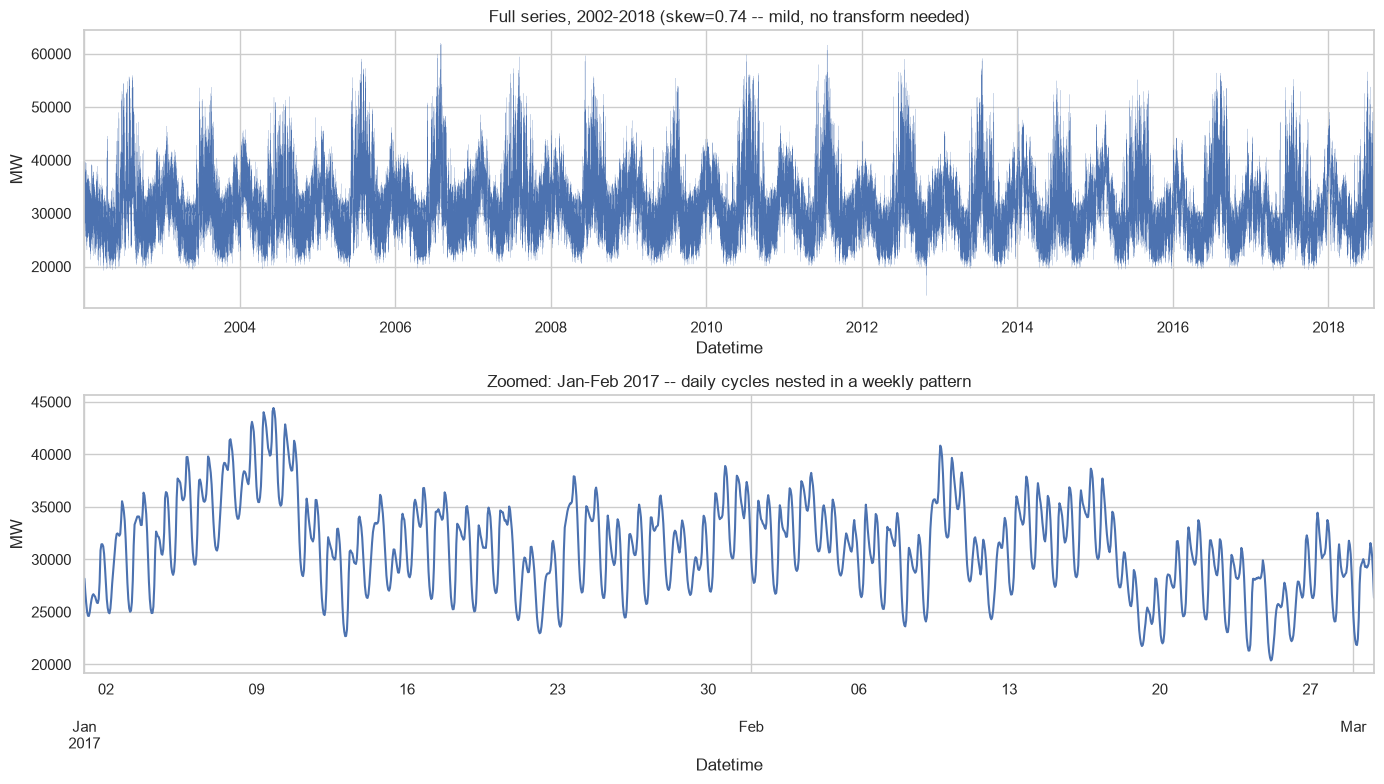

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

df["PJME_MW"].plot(ax=axes[0], linewidth=0.1)
axes[0].set_title(f"Full series, 2002-2018 (skew={df['PJME_MW'].skew():.2f} -- mild, no transform needed)")
axes[0].set_ylabel("MW")

df["PJME_MW"].loc["2017-01-01":"2017-03-01"].plot(ax=axes[1])
axes[1].set_title("Zoomed: Jan-Feb 2017 -- daily cycles nested in a weekly pattern")
axes[1].set_ylabel("MW")

plt.tight_layout()
plt.show()


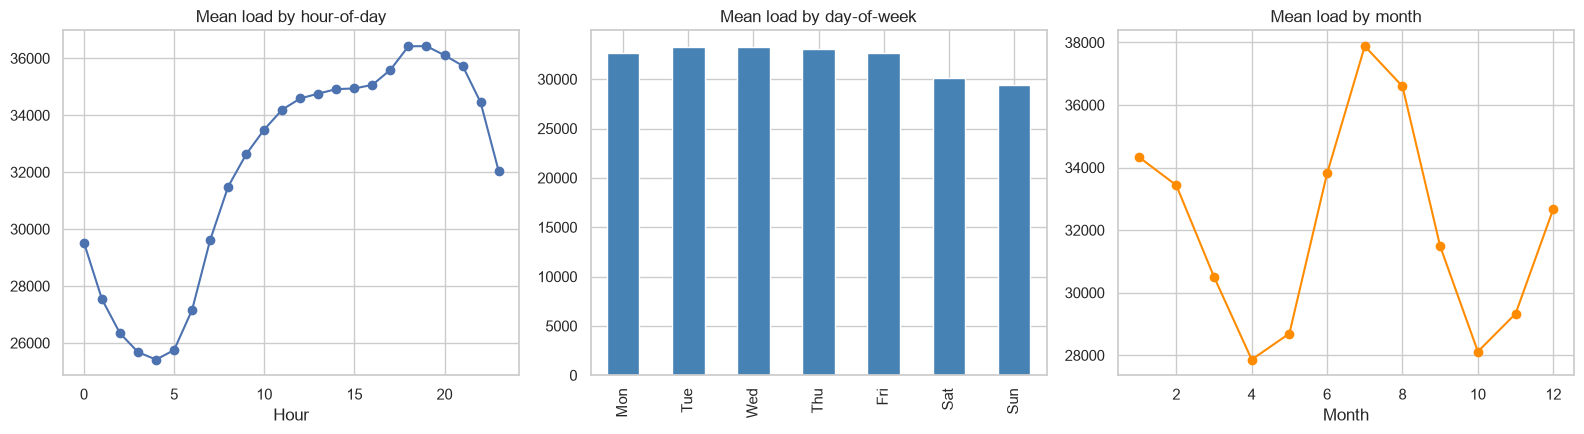

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

hourly = df.groupby(df.index.hour)["PJME_MW"].mean()
hourly.plot(kind="line", marker="o", ax=axes[0])
axes[0].set_title("Mean load by hour-of-day")
axes[0].set_xlabel("Hour")

dow = df.groupby(df.index.dayofweek)["PJME_MW"].mean()
dow.index = ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"]
dow.plot(kind="bar", ax=axes[1], color="steelblue")
axes[1].set_title("Mean load by day-of-week")

monthly = df.groupby(df.index.month)["PJME_MW"].mean()
monthly.plot(kind="line", marker="o", ax=axes[2], color="darkorange")
axes[2].set_title("Mean load by month")
axes[2].set_xlabel("Month")

plt.tight_layout()
plt.show()


Three textbook electricity-demand patterns, all real: a **double-peaked
daily cycle** (morning ramp-up, evening peak), **lower weekend demand**
(commercial/industrial load drops on Sat/Sun), and a **summer peak with a smaller
winter bump** (AC load dominates PJM East's climate, with heating adding a
secondary peak). Every one of these is a feature the models below get to use
directly.


### Feature engineering: the "turn a time series into a table" recipe

- **Calendar features** — `hour`, `dayofweek`, `month`, `is_weekend` — directly
  encode the seasonality patterns just plotted.
- **Lag features** — the load exactly 1 hour, 24 hours (same hour yesterday), and
  168 hours (same hour last week) ago. These are the strongest predictors in most
  load-forecasting setups, by a wide margin.
- **Rolling features** — trailing 24-hour and 168-hour mean/std, capturing recent
  trend and volatility beyond any single lag point.

Every one of these uses only *past* information relative to the row's own
timestamp — predicting the future from the future would make the whole exercise
meaningless.


In [5]:
feat = df.copy()
feat["hour"] = feat.index.hour
feat["dayofweek"] = feat.index.dayofweek
feat["month"] = feat.index.month
feat["is_weekend"] = (feat["dayofweek"] >= 5).astype(int)

for lag in [1, 24, 168]:
    feat[f"lag_{lag}"] = feat["PJME_MW"].shift(lag)

feat["rolling_mean_24"] = feat["PJME_MW"].shift(1).rolling(24).mean()
feat["rolling_std_24"] = feat["PJME_MW"].shift(1).rolling(24).std()
feat["rolling_mean_168"] = feat["PJME_MW"].shift(1).rolling(168).mean()

before = len(feat)
feat = feat.dropna().reset_index()
print(f"Rows before -> after dropping the initial week with no full lag/rolling history: "
      f"{before} -> {len(feat)}")

numeric_features = ["hour", "dayofweek", "month", "is_weekend",
                     "lag_1", "lag_24", "lag_168",
                     "rolling_mean_24", "rolling_std_24", "rolling_mean_168"]

X = feat[numeric_features]
y = feat["PJME_MW"]

feat[numeric_features + ["PJME_MW"]].describe()


Rows before -> after dropping the initial week with no full lag/rolling history: 145392 -> 145224


,hour,dayofweek,month,is_weekend,lag_1,lag_24,lag_168,rolling_mean_24,rolling_std_24,rolling_mean_168,PJME_MW
count,145224.00000,145224.000000,145224.000000,145224.000000,145224.000000,145224.000000,145224.000000,145224.000000,145224.000000,145224.000000,145224.000000
mean,11.50000,2.999525,6.442124,0.285573,32078.388369,32077.414701,32074.530474,32077.856086,4245.371936,32075.850795,32078.417972
std,6.92221,1.999712,3.435979,0.451688,6466.674928,6465.770698,6462.689170,4686.920099,1637.572724,3983.087905,6466.680687
min,0.00000,0.000000,1.000000,0.000000,14544.000000,14544.000000,14544.000000,19307.416667,1040.007859,24334.416667,14544.000000
25%,5.75000,1.000000,3.000000,0.000000,27569.000000,27568.000000,27569.000000,28604.187500,3108.372301,28752.136905,27569.000000
50%,11.50000,3.000000,6.000000,0.000000,31419.000000,31419.000000,31418.000000,31324.291667,3742.078450,31461.848214,31419.000000
75%,17.25000,5.000000,9.000000,1.000000,35647.000000,35646.000000,35639.000000,34974.635417,5094.741999,34801.668155,35647.000000
max,23.00000,6.000000,12.000000,1.000000,62009.000000,62009.000000,62009.000000,52261.416667,11014.844383,47230.702381,62009.000000


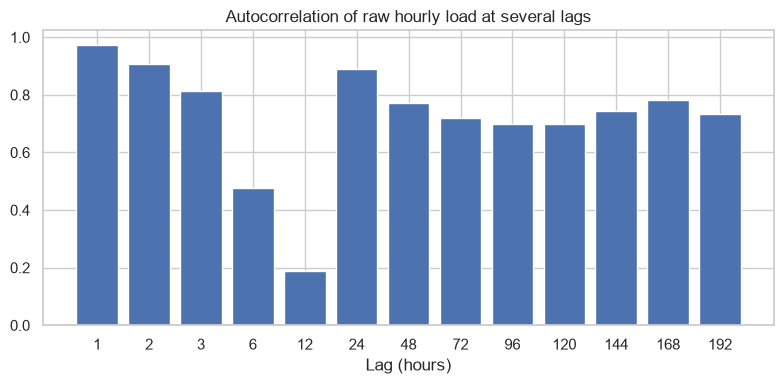

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
acs = [df["PJME_MW"].autocorr(lag=l) for l in [1, 2, 3, 6, 12, 24, 48, 72, 96, 120, 144, 168, 192]]
ax.bar([str(l) for l in [1, 2, 3, 6, 12, 24, 48, 72, 96, 120, 144, 168, 192]], acs)
ax.set_title("Autocorrelation of raw hourly load at several lags")
ax.set_xlabel("Lag (hours)")
ax.axhline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()


Autocorrelation barely decays even out to a week (168 hours) — load at the
same hour next week looks almost as similar as load one hour from now. This is
*much* stronger persistence than the crypto notebook's volatility (which decayed
to near zero within ~10 lags) — a genuinely easier forecasting problem, and the
`lag_168`/`rolling_mean_168` features exist specifically to capture it.


## 3. Time-aware train/test split

The same reasoning as the crypto microstructure notebook: this is autocorrelated
time-series data, so both the train/test split and every cross-validation fold
below use chronological order, never a random shuffle. We hold out the final
year (2018's partial + the preceding months to make a clean year) as test.


In [7]:
cutoff = X.shape[0] - 24 * 365  # last ~365 days as test
X_train, X_test = X.iloc[:cutoff], X.iloc[cutoff:]
y_train, y_test = y.iloc[:cutoff], y.iloc[cutoff:]
dates_test = feat["Datetime"].iloc[cutoff:]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

tscv = TimeSeriesSplit(n_splits=2)

print(f"Train: {X_train.shape} ({feat['Datetime'].iloc[0]} to {feat['Datetime'].iloc[cutoff-1]})")
print(f"Test:  {X_test.shape} ({feat['Datetime'].iloc[cutoff]} to {feat['Datetime'].iloc[-1]})")


Train: (136464, 10) (2002-01-08 01:00:00 to 2017-08-03 00:00:00)
Test:  (8760, 10) (2017-08-03 01:00:00 to 2018-08-03 00:00:00)


In [8]:
results = {}

def evaluate(name, y_true, y_pred):
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    mape = (np.abs((y_true - y_pred) / y_true)).mean() * 100
    results[name] = {"RMSE": rmse, "MAE": mae, "R2": r2, "MAPE_%": mape}
    print(f"{name:16s}  RMSE={rmse:.1f}   MAE={mae:.1f}   R2={r2:.4f}   MAPE={mape:.2f}%")
    return rmse, mae, r2


## 4. Linear Regression

With `lag_1`/`lag_24`/`lag_168` doing most of the work, and the relationship
between "load an hour ago" and "load now" being close to linear, expect this
baseline to do unusually well for a "plain OLS" model.


In [9]:
lin_reg = LinearRegression()
lin_reg.fit(X_train_scaled, y_train)
y_pred_lr = lin_reg.predict(X_test_scaled)
evaluate("LinearRegression", y_test, y_pred_lr)


LinearRegression  RMSE=1228.9   MAE=964.8   R2=0.9588   MAPE=3.11%


(1228.9368009441957, 964.7891571510552, 0.9588317585339905)

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98352/746690973.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=coef_df, x="coefficient", y="feature", palette="viridis")


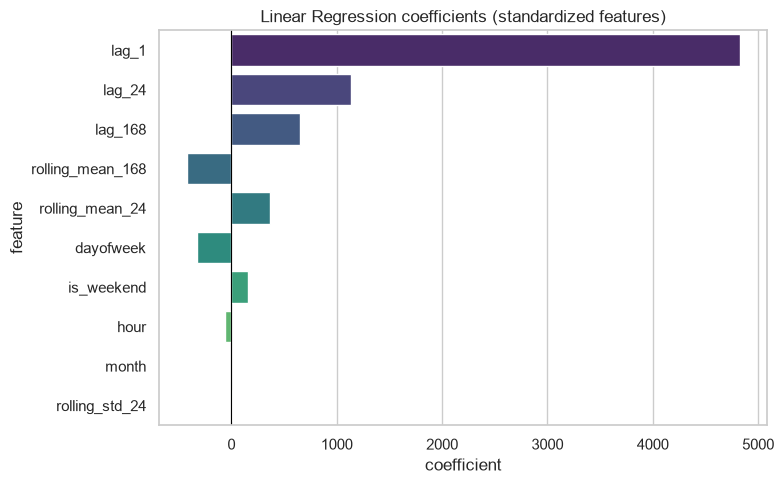

,feature,coefficient
4,lag_1,4823.846491
5,lag_24,1138.380085
6,lag_168,647.867675
9,rolling_mean_168,-421.722823
7,rolling_mean_24,364.002535
1,dayofweek,-323.557586
3,is_weekend,158.745277
0,hour,-62.654837
2,month,-7.654900
8,rolling_std_24,2.784364


In [10]:
coef_df = pd.DataFrame({"feature": numeric_features, "coefficient": lin_reg.coef_}
                       ).sort_values("coefficient", key=abs, ascending=False)
plt.figure(figsize=(8, 5))
sns.barplot(data=coef_df, x="coefficient", y="feature", palette="viridis")
plt.title("Linear Regression coefficients (standardized features)")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()
coef_df


## 5. Regularized Linear Models: Ridge, Lasso & Elastic Net

The three lag features and the two rolling-mean features are all substantially
correlated with each other (they're all "load, recently") — a textbook
multicollinearity setup, more pronounced than in any previous notebook.


In [11]:
alphas = np.logspace(-2, 2, 3)

ridge = RidgeCV(alphas=alphas, cv=tscv)
ridge.fit(X_train_scaled, y_train)
y_pred_ridge = ridge.predict(X_test_scaled)
evaluate("Ridge", y_test, y_pred_ridge)
print(f"Chosen alpha: {ridge.alpha_:.4f}")


Ridge             RMSE=1228.9   MAE=964.8   R2=0.9588   MAPE=3.11%
Chosen alpha: 0.0100


In [12]:
lasso = LassoCV(alphas=alphas, cv=tscv, max_iter=5000, random_state=RANDOM_STATE)
lasso.fit(X_train_scaled, y_train)
y_pred_lasso = lasso.predict(X_test_scaled)
evaluate("Lasso", y_test, y_pred_lasso)
print(f"Chosen alpha: {lasso.alpha_:.4f}")
print(f"Features zeroed out: {(lasso.coef_ == 0).sum()} / {len(lasso.coef_)}")


Lasso             RMSE=1228.9   MAE=964.8   R2=0.9588   MAPE=3.11%
Chosen alpha: 0.0100
Features zeroed out: 0 / 10


In [13]:
elastic = ElasticNetCV(alphas=alphas, l1_ratio=[.5],
                        cv=tscv, max_iter=5000, random_state=RANDOM_STATE)
elastic.fit(X_train_scaled, y_train)
y_pred_elastic = elastic.predict(X_test_scaled)
evaluate("ElasticNet", y_test, y_pred_elastic)
print(f"Chosen alpha: {elastic.alpha_:.4f}, l1_ratio: {elastic.l1_ratio_:.2f}")
print(f"Features zeroed out: {(elastic.coef_ == 0).sum()} / {len(elastic.coef_)}")


ElasticNet        RMSE=1238.7   MAE=971.1   R2=0.9582   MAPE=3.12%
Chosen alpha: 0.0100, l1_ratio: 0.50
Features zeroed out: 0 / 10


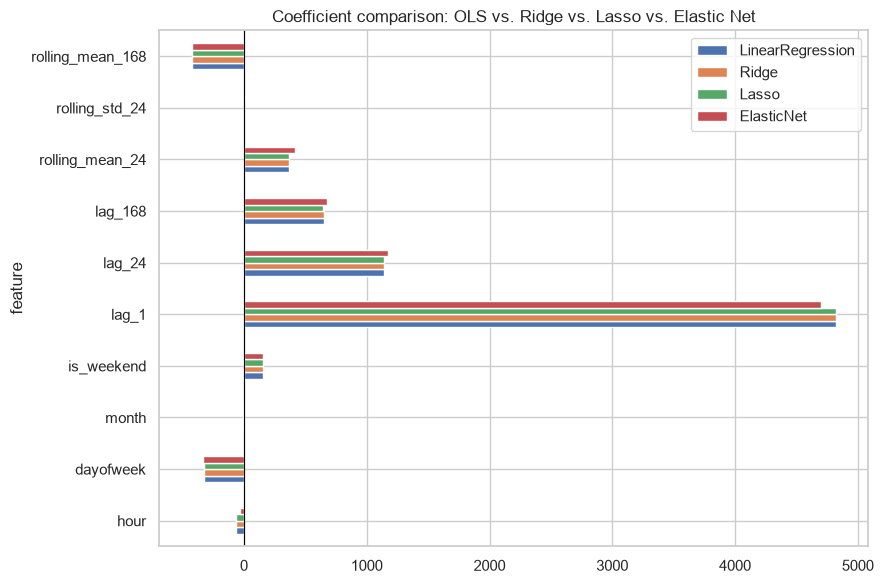

,LinearRegression,Ridge,Lasso,ElasticNet
feature,,,,
hour,-62.654837,-62.654369,-62.618128,-31.774748
dayofweek,-323.557586,-323.557744,-323.493126,-333.186768
month,-7.654900,-7.654916,-7.641985,-8.802202
is_weekend,158.745277,158.745245,158.655322,155.645510
lag_1,4823.846491,4823.844540,4823.884422,4696.881303
lag_24,1138.380085,1138.380654,1138.365123,1175.207736
lag_168,647.867675,647.868107,647.791053,675.140950
rolling_mean_24,364.002535,364.003297,363.908819,411.835551
rolling_std_24,2.784364,2.784417,2.774451,6.702113


In [14]:
coef_compare = pd.DataFrame({
    "feature": numeric_features, "LinearRegression": lin_reg.coef_,
    "Ridge": ridge.coef_, "Lasso": lasso.coef_, "ElasticNet": elastic.coef_,
}).set_index("feature")
coef_compare.plot(kind="barh", figsize=(9, 6))
plt.title("Coefficient comparison: OLS vs. Ridge vs. Lasso vs. Elastic Net")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()
coef_compare


Lasso/Elastic Net typically zero out one of `rolling_mean_24`/`lag_24` here —
confirming the multicollinearity story directly: once the model has one good
"recent load level" signal, a second, highly correlated one adds little.


## 6. K-Nearest Neighbors (KNN)

A genuinely different kind of model from everything else in this notebook: KNN
has no coefficients and builds no trees. It predicts a point's target by
averaging the targets of its `k` nearest training points in feature space —
"nearest" measured on the *scaled* features (the same `X_train_scaled`/
`X_test_scaled` used by the linear models and MLP above), since distance is
meaningless once features sit on wildly different raw scales.

**When to reach for it:** a quick, assumption-light baseline — no linearity, no
tree-splittable structure, nothing learned at "training" time (there's no
training at all; `.fit()` just stores the data).

**Key hyperparameters:**
- `n_neighbors` (k): more neighbors → smoother, more biased predictions; fewer →
  noisier, more variance.
- `weights`: `"uniform"` averages neighbors equally; `"distance"` weights closer
  neighbors more heavily.
- `p`: the distance metric's power — `1` = Manhattan, `2` = Euclidean.

**Limitations:** prediction is slow on large datasets (every query compares
against the full training set); accuracy degrades in high dimensions (the
"curse of dimensionality" — with enough dimensions, every point ends up roughly
equidistant from every other).


In [15]:
knn = KNeighborsRegressor(n_neighbors=15, weights="distance")
knn.fit(X_train_scaled, y_train)

y_pred_knn = knn.predict(X_test_scaled)
evaluate("KNN", y_test, y_pred_knn)


KNN               RMSE=1134.2   MAE=869.4   R2=0.9649   MAPE=2.78%


(1134.2243155696647, 869.4104217793458, 0.9649327972711288)

### Hyperparameter tuning with `GridSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [16]:
knn_param_grid = {'n_neighbors': [5, 15], 'weights': ['distance'], 'p': [2]}


knn_grid = GridSearchCV(
    KNeighborsRegressor(),
    param_grid=knn_param_grid,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
    n_jobs=2,
)
knn_grid.fit(X_train_scaled, y_train)

print(f"Best params: {knn_grid.best_params_}")
print(f"Best CV RMSE: {-knn_grid.best_score_:.4f}")


Best params: {'n_neighbors': 15, 'p': 2, 'weights': 'distance'}
Best CV RMSE: 1096.2478


In [17]:
y_pred_knn_tuned = knn_grid.best_estimator_.predict(X_test_scaled)
evaluate("KNN (tuned)", y_test, y_pred_knn_tuned)


KNN (tuned)       RMSE=1134.2   MAE=869.4   R2=0.9649   MAPE=2.78%


(1134.2243155696647, 869.4104217793458, 0.9649327972711288)

## 7. MLP (Multi-Layer Perceptron)


In [18]:
mlp = MLPRegressor(
    hidden_layer_sizes=(64, 32), activation="relu", alpha=1e-4,
    learning_rate_init=1e-3, max_iter=500, early_stopping=True,
    n_iter_no_change=15, random_state=RANDOM_STATE,
)
mlp.fit(X_train_scaled, y_train)
y_pred_mlp = mlp.predict(X_test_scaled)
evaluate("MLP", y_test, y_pred_mlp)


MLP               RMSE=534.7   MAE=395.4   R2=0.9922   MAPE=1.24%


(534.6546175610881, 395.4071632293288, 0.9922079835438689)

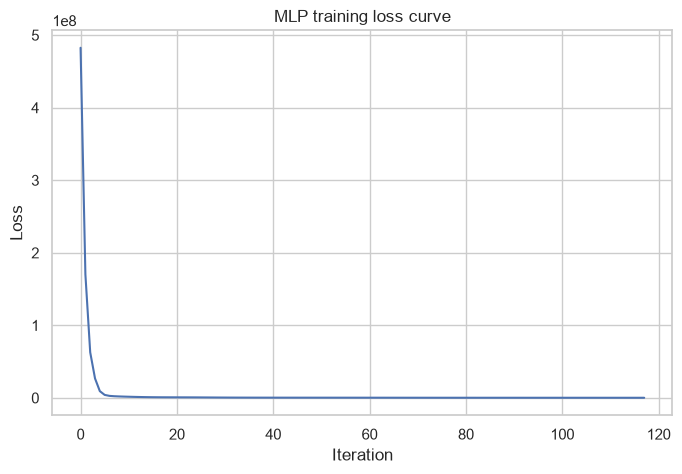

In [19]:
plt.plot(mlp.loss_curve_)
plt.title("MLP training loss curve")
plt.xlabel("Iteration"); plt.ylabel("Loss")
plt.show()


### Hyperparameter tuning with `RandomizedSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [20]:
mlp_param_dist = {'hidden_layer_sizes': [(64, 32)], 'alpha': [0.0001, 0.001]}


mlp_search = RandomizedSearchCV(
    MLPRegressor(activation="relu", learning_rate_init=1e-3, max_iter=500,
                 early_stopping=True, n_iter_no_change=15, random_state=RANDOM_STATE),
    param_distributions=mlp_param_dist, n_iter=2, cv=tscv,
    scoring="neg_root_mean_squared_error", n_jobs=2, random_state=RANDOM_STATE,
)
mlp_search.fit(X_train_scaled, y_train)
print(f"Best params: {mlp_search.best_params_}")
print(f"Best CV RMSE: {-mlp_search.best_score_:.1f}")


Best params: {'hidden_layer_sizes': (64, 32), 'alpha': 0.001}
Best CV RMSE: 622.5


In [21]:
y_pred_mlp_tuned = mlp_search.best_estimator_.predict(X_test_scaled)
evaluate("MLP (tuned)", y_test, y_pred_mlp_tuned)


MLP (tuned)       RMSE=524.4   MAE=389.1   R2=0.9925   MAPE=1.22%


(524.4235012182093, 389.0859302919412, 0.9925033452824397)

## 8. Random Forest


In [22]:
rf = RandomForestRegressor(n_estimators=300, max_depth=None, min_samples_leaf=2,
                            n_jobs=2, random_state=RANDOM_STATE)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
evaluate("RandomForest", y_test, y_pred_rf)


RandomForest      RMSE=430.9   MAE=311.1   R2=0.9949   MAPE=0.97%


(430.87681797686446, 311.13570438253504, 0.9949393130299606)

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98352/1071758327.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=rf_importance, x="importance", y="feature", palette="viridis")


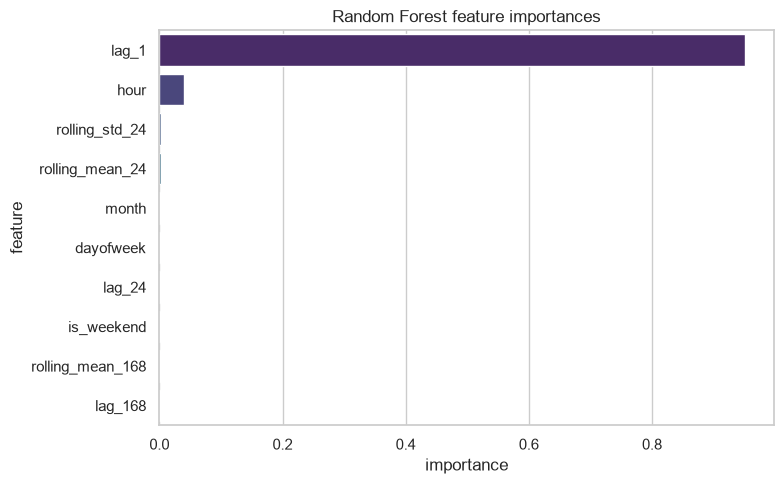

,feature,importance
4,lag_1,0.950561
0,hour,0.039701
8,rolling_std_24,0.003198
7,rolling_mean_24,0.001831
2,month,0.001185
1,dayofweek,0.000973
5,lag_24,0.000847
3,is_weekend,0.000660
9,rolling_mean_168,0.000547
6,lag_168,0.000497


In [23]:
rf_importance = pd.DataFrame({"feature": numeric_features, "importance": rf.feature_importances_}
                             ).sort_values("importance", ascending=False)
plt.figure(figsize=(8, 5))
sns.barplot(data=rf_importance, x="importance", y="feature", palette="viridis")
plt.title("Random Forest feature importances")
plt.tight_layout()
plt.show()
rf_importance


### Hyperparameter tuning with `RandomizedSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [24]:
rf_param_dist = {'n_estimators': [300], 'max_depth': [8, 12], 'min_samples_leaf': [2, 5]}


rf_search = RandomizedSearchCV(
    RandomForestRegressor(n_jobs=2, random_state=RANDOM_STATE),
    param_distributions=rf_param_dist, n_iter=2, cv=tscv,
    scoring="neg_root_mean_squared_error", n_jobs=2, random_state=RANDOM_STATE,
)
rf_search.fit(X_train, y_train)
print(f"Best params: {rf_search.best_params_}")
print(f"Best CV RMSE: {-rf_search.best_score_:.1f}")


Best params: {'n_estimators': 300, 'min_samples_leaf': 5, 'max_depth': 12}
Best CV RMSE: 525.5


In [25]:
y_pred_rf_tuned = rf_search.best_estimator_.predict(X_test)
evaluate("RandomForest (tuned)", y_test, y_pred_rf_tuned)


RandomForest (tuned)  RMSE=516.7   MAE=376.9   R2=0.9927   MAPE=1.18%


(516.7157892592235, 376.8811320594227, 0.9927220899776807)

## 9. XGBoost (Extreme Gradient Boosting)


In [26]:
xgb = XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=5,
                    subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
                    random_state=RANDOM_STATE, n_jobs=2)
xgb.fit(X_train, y_train, eval_set=[(X_test, y_test)], verbose=False)
y_pred_xgb = xgb.predict(X_test)
evaluate("XGBoost", y_test, y_pred_xgb)


XGBoost           RMSE=452.4   MAE=340.3   R2=0.9944   MAPE=1.07%


(452.4238799319056, 340.28600996182934, 0.9944205131689)

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98352/3000457602.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=xgb_importance, x="importance", y="feature", palette="viridis")


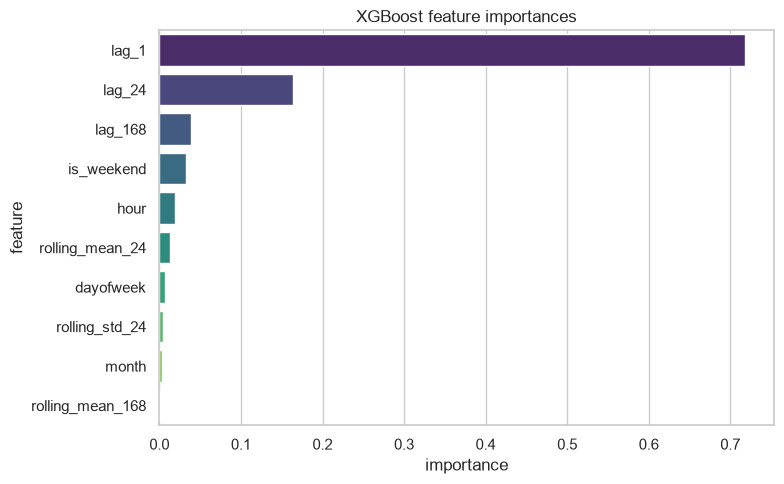

,feature,importance
4,lag_1,0.717647
5,lag_24,0.163355
6,lag_168,0.038751
3,is_weekend,0.033114
0,hour,0.019726
7,rolling_mean_24,0.013002
1,dayofweek,0.006345
8,rolling_std_24,0.004292
2,month,0.002746
9,rolling_mean_168,0.001021


In [27]:
xgb_importance = pd.DataFrame({"feature": numeric_features, "importance": xgb.feature_importances_}
                              ).sort_values("importance", ascending=False)
plt.figure(figsize=(8, 5))
sns.barplot(data=xgb_importance, x="importance", y="feature", palette="viridis")
plt.title("XGBoost feature importances")
plt.tight_layout()
plt.show()
xgb_importance


### Hyperparameter tuning with `RandomizedSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [28]:
xgb_param_dist = {'n_estimators': [500], 'max_depth': [3, 5], 'learning_rate': [0.03, 0.05]}


xgb_search = RandomizedSearchCV(
    XGBRegressor(subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
                 random_state=RANDOM_STATE, n_jobs=2),
    param_distributions=xgb_param_dist, n_iter=2, cv=tscv,
    scoring="neg_root_mean_squared_error", n_jobs=2, random_state=RANDOM_STATE,
)
xgb_search.fit(X_train, y_train)
print(f"Best params: {xgb_search.best_params_}")
print(f"Best CV RMSE: {-xgb_search.best_score_:.1f}")


Best params: {'n_estimators': 500, 'max_depth': 5, 'learning_rate': 0.05}
Best CV RMSE: 450.2


In [29]:
y_pred_xgb_tuned = xgb_search.best_estimator_.predict(X_test)
evaluate("XGBoost (tuned)", y_test, y_pred_xgb_tuned)


XGBoost (tuned)   RMSE=452.4   MAE=340.3   R2=0.9944   MAPE=1.07%


(452.4238799319056, 340.28600996182934, 0.9944205131689)

## 10. CatBoost (Categorical Boosting)

All-numeric feature set (no symbol/venue-style categoricals here), so plain
`CatBoostRegressor` with no `cat_features`.


In [30]:
cat = CatBoostRegressor(iterations=500, learning_rate=0.05, depth=6, l2_leaf_reg=3.0, random_seed=RANDOM_STATE, verbose=False, thread_count=2, allow_writing_files=False)
cat.fit(X_train, y_train, eval_set=(X_test, y_test), use_best_model=True)
y_pred_cat = cat.predict(X_test)
evaluate("CatBoost", y_test, y_pred_cat)


CatBoost          RMSE=451.1   MAE=338.7   R2=0.9945   MAPE=1.06%


(451.1094796561299, 338.66884543714883, 0.9944528855802729)

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98352/3646199671.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cat_importance, x="importance", y="feature", palette="viridis")


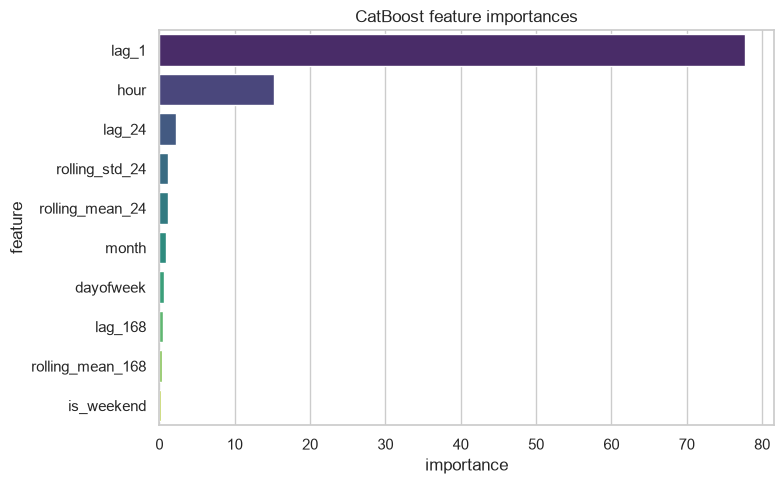

,feature,importance
4,lag_1,77.691175
0,hour,15.258010
5,lag_24,2.206035
8,rolling_std_24,1.166563
7,rolling_mean_24,1.140268
2,month,0.846506
1,dayofweek,0.638662
6,lag_168,0.517765
9,rolling_mean_168,0.349217
3,is_weekend,0.185800


In [31]:
cat_importance = pd.DataFrame({"feature": numeric_features, "importance": cat.get_feature_importance()}
                               ).sort_values("importance", ascending=False)
plt.figure(figsize=(8, 5))
sns.barplot(data=cat_importance, x="importance", y="feature", palette="viridis")
plt.title("CatBoost feature importances")
plt.tight_layout()
plt.show()
cat_importance


### Hyperparameter tuning with `RandomizedSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [32]:
cat_param_dist = {'iterations': [500], 'depth': [4, 6], 'learning_rate': [0.03, 0.05]}


cat_search = RandomizedSearchCV(
    CatBoostRegressor(l2_leaf_reg=3.0, random_seed=RANDOM_STATE, thread_count=1, allow_writing_files=False, verbose=False),
    param_distributions=cat_param_dist, n_iter=2, cv=tscv,
    scoring="neg_root_mean_squared_error", n_jobs=2, random_state=RANDOM_STATE,
)
cat_search.fit(X_train, y_train)
print(f"Best params: {cat_search.best_params_}")
print(f"Best CV RMSE: {-cat_search.best_score_:.1f}")


Best params: {'learning_rate': 0.05, 'iterations': 500, 'depth': 6}
Best CV RMSE: 433.8


In [33]:
y_pred_cat_tuned = cat_search.best_estimator_.predict(X_test)
evaluate("CatBoost (tuned)", y_test, y_pred_cat_tuned)


CatBoost (tuned)  RMSE=451.1   MAE=338.7   R2=0.9945   MAPE=1.06%


(451.1094796561299, 338.66884543714883, 0.9944528855802729)

## 11. LightGBM (Light Gradient Boosting Machine)


In [34]:
lgbm = LGBMRegressor(n_estimators=500, learning_rate=0.05, num_leaves=31,
                      min_child_samples=20, subsample=0.8, colsample_bytree=0.8,
                      random_state=RANDOM_STATE, n_jobs=2, verbose=-1)
lgbm.fit(X_train, y_train, eval_set=[(X_test, y_test)])
y_pred_lgbm = lgbm.predict(X_test)
evaluate("LightGBM", y_test, y_pred_lgbm)


LightGBM          RMSE=439.8   MAE=332.9   R2=0.9947   MAPE=1.05%


(439.75645623956996, 332.9425788076001, 0.9947285794465206)

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98352/3205230767.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=lgbm_importance, x="importance", y="feature", palette="viridis")


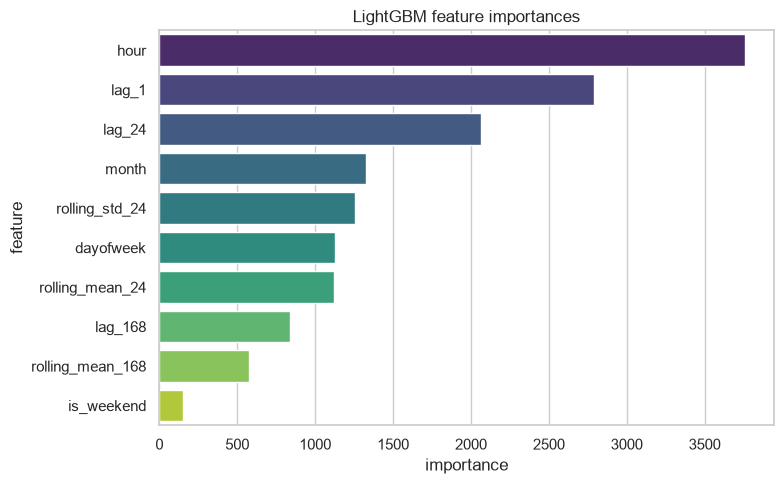

,feature,importance
0,hour,3757
4,lag_1,2790
5,lag_24,2063
2,month,1329
8,rolling_std_24,1254
1,dayofweek,1126
7,rolling_mean_24,1119
6,lag_168,841
9,rolling_mean_168,572
3,is_weekend,149


In [35]:
lgbm_importance = pd.DataFrame({"feature": numeric_features, "importance": lgbm.feature_importances_}
                                ).sort_values("importance", ascending=False)
plt.figure(figsize=(8, 5))
sns.barplot(data=lgbm_importance, x="importance", y="feature", palette="viridis")
plt.title("LightGBM feature importances")
plt.tight_layout()
plt.show()
lgbm_importance


### Hyperparameter tuning with `RandomizedSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [36]:
lgbm_param_dist = {'n_estimators': [500], 'num_leaves': [15, 31], 'learning_rate': [0.03, 0.05]}


lgbm_search = RandomizedSearchCV(
    LGBMRegressor(subsample=0.8, colsample_bytree=0.8, min_child_samples=20,
                  random_state=RANDOM_STATE, n_jobs=2, verbose=-1),
    param_distributions=lgbm_param_dist, n_iter=2, cv=tscv,
    scoring="neg_root_mean_squared_error", n_jobs=2, random_state=RANDOM_STATE,
)
lgbm_search.fit(X_train, y_train)
print(f"Best params: {lgbm_search.best_params_}")
print(f"Best CV RMSE: {-lgbm_search.best_score_:.1f}")


Best params: {'num_leaves': 31, 'n_estimators': 500, 'learning_rate': 0.05}
Best CV RMSE: 438.5


In [37]:
y_pred_lgbm_tuned = lgbm_search.best_estimator_.predict(X_test)
evaluate("LightGBM (tuned)", y_test, y_pred_lgbm_tuned)


LightGBM (tuned)  RMSE=439.8   MAE=332.9   R2=0.9947   MAPE=1.05%


(439.75645623956996, 332.9425788076001, 0.9947285794465206)

## 12. ARIMA and SARIMA

Every model above is still a tabular regressor: it never sees the series as a
sequence, only the lag and calendar columns we built for it. **ARIMA(p, d, q)**
is the classical alternative. It models the load itself — an autoregressive piece
(p lags of the series), a moving-average piece (q lags of the shock), after
differencing d times so the level doesn't wander.

Hourly load also repeats every day, which is why the autocorrelation plot peaked
again at 24 hours. **SARIMA** adds a second ARIMA at that seasonal period:
`(P, D, Q, s)` with `s=24`. A weekly period (`s=168`) is the same idea, but the
seasonal state becomes enormous; the tabular models already get that cycle from
`lag_168`, so the seasonal model here stays on the daily cycle.

Two evaluation details, so this stays comparable to the table above:

- Those models are **one-step-ahead**. `lag_1` is the previous hour's *actual*
  load, not the model's own previous guess. SARIMA gets the same protocol: fit the
  coefficients once, then `extend` them through the test year so each hour's
  prediction can use the actual load that just arrived. A pure multi-day forecast
  (no test actuals) is a harder problem and is plotted separately, not scored in
  the table.
- The fit uses the **full training history of training data**, not all 16 years. A local
  seasonal model doesn't need the distant history, and the state-space likelihood
  on ~136,000 hours is much slower for almost the same one-step forecast.


In [38]:
load = df["PJME_MW"].iloc[168:]
arima_train = load.iloc[:cutoff]
print(f"ARIMA/SARIMA training hours: {len(arima_train):,}")
specifications = [
    ("ARIMA", (2, 1, 2), (0, 0, 0, 0)),
    ("SARIMA", (1, 1, 1), (1, 0, 1, 24)),
    ("SARIMA", (2, 1, 2), (1, 1, 1, 24)),
]
fitted = []
sarima_predictions = {}
for name, order, seasonal_order in specifications:
    print(f"Fitting {name} {order}, seasonal order {seasonal_order}", flush=True)
    model = SARIMAX(arima_train, order=order, seasonal_order=seasonal_order,
                    enforce_stationarity=False, enforce_invertibility=False)
    result = model.fit(disp=False, maxiter=100, low_memory=True)
    # Start test filtering from the final training state. Each observed test
    # hour updates the state before predicting the following hour.
    final_state = result.filter_results.predicted_state[:, -1]
    final_covariance = result.filter_results.predicted_state_cov[:, :, -1]
    test_model = SARIMAX(load.iloc[cutoff:], order=order, seasonal_order=seasonal_order,
                        enforce_stationarity=False, enforce_invertibility=False,
                        initialization="known", initial_state=final_state,
                        initial_state_cov=final_covariance)
    prediction = test_model.filter(result.params).fittedvalues.to_numpy()
    if name == "ARIMA":
        arima = result
        y_pred_arima = prediction
        evaluate("ARIMA", y_test, y_pred_arima)
    else:
        fitted.append((result.aic, order, seasonal_order, result))
        sarima_predictions[(order, seasonal_order)] = prediction
fitted.sort(key=lambda row: row[0])
order_table = pd.DataFrame([{"order": str(order), "seasonal_order": str(seasonal), "AIC": aic}
                            for aic, order, seasonal, _ in fitted])
print(order_table.to_string(index=False))
sarima = fitted[0][3]
print(sarima.summary())
y_pred_sarima = sarima_predictions[(fitted[0][1], fitted[0][2])]
evaluate("SARIMA", y_test, y_pred_sarima)


ARIMA/SARIMA training hours: 136,464
Fitting ARIMA (2, 1, 2), seasonal order (0, 0, 0, 0)


ARIMA             RMSE=551.4   MAE=399.4   R2=0.9917   MAPE=1.26%
Fitting SARIMA (1, 1, 1), seasonal order (1, 0, 1, 24)


Fitting SARIMA (2, 1, 2), seasonal order (1, 1, 1, 24)


    order seasonal_order          AIC
(2, 1, 2)  (1, 1, 1, 24) 1.963436e+06
(1, 1, 1)  (1, 0, 1, 24) 1.977220e+06


                                      SARIMAX Results                                       
Dep. Variable:                              PJME_MW   No. Observations:               136464
Model:             SARIMAX(2, 1, 2)x(1, 1, [1], 24)   Log Likelihood             -981710.965
Date:                              Mon, 19 Oct 2026   AIC                        1963435.930
Time:                                      20:41:56   BIC                        1963504.694
Sample:                                  01-08-2002   HQIC                       1963456.511
                                       - 08-03-2017                                         
Covariance Type:                             approx                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2454      0.024     10.308      0.000       0.199       0.292
ar.L2          0.03

(287.1979798046258, 207.99915955320202, 0.997751639336172)

14-day open-loop forecast  RMSE=4426.7   (one-step SARIMA over the full test year: RMSE=287.2)


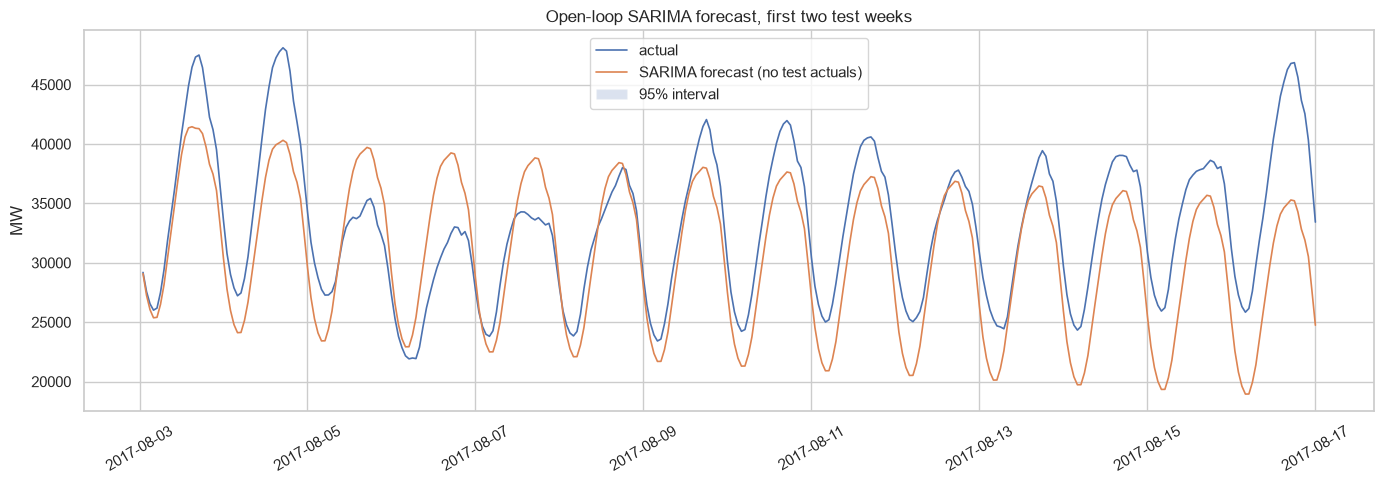

In [39]:
horizon = 24 * 14  # two weeks, matching the comparison plot below
forecast = sarima.get_forecast(steps=horizon)
mean = forecast.predicted_mean
ci = forecast.conf_int(alpha=0.05)
open_rmse = mean_squared_error(y_test.iloc[:horizon], mean.to_numpy()) ** 0.5
print(f"14-day open-loop forecast  RMSE={open_rmse:.1f}   "
      f"(one-step SARIMA over the full test year: RMSE={results['SARIMA']['RMSE']:.1f})")

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(mean.index, y_test.values[:horizon], label="actual", linewidth=1.2)
ax.plot(mean.index, mean.values, label="SARIMA forecast (no test actuals)", linewidth=1.2)
ax.fill_between(mean.index, ci.iloc[:, 0], ci.iloc[:, 1], alpha=0.2, label="95% interval")
ax.set_title("Open-loop SARIMA forecast, first two test weeks")
ax.set_ylabel("MW")
ax.legend()
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()


## 13. Head-to-head comparison


In [40]:
results_df = pd.DataFrame(results).T.sort_values("RMSE")
results_df


,RMSE,MAE,R2,MAPE_%
SARIMA,287.197980,207.999160,0.997752,0.677511
RandomForest,430.876818,311.135704,0.994939,0.972176
LightGBM,439.756456,332.942579,0.994729,1.052974
LightGBM (tuned),439.756456,332.942579,0.994729,1.052974
CatBoost,451.109480,338.668845,0.994453,1.064652
CatBoost (tuned),451.109480,338.668845,0.994453,1.064652
XGBoost,452.423880,340.286010,0.994421,1.070805
XGBoost (tuned),452.423880,340.286010,0.994421,1.070805
RandomForest (tuned),516.715789,376.881132,0.992722,1.177050
MLP (tuned),524.423501,389.085930,0.992503,1.216882


/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98352/4075352090.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=results_df.loc[order, metric], y=order, palette="viridis", ax=ax)
/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98352/4075352090.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=results_df.loc[order, metric], y=order, palette="viridis", ax=ax)
/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98352/4075352090.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=results_df.loc[order, met

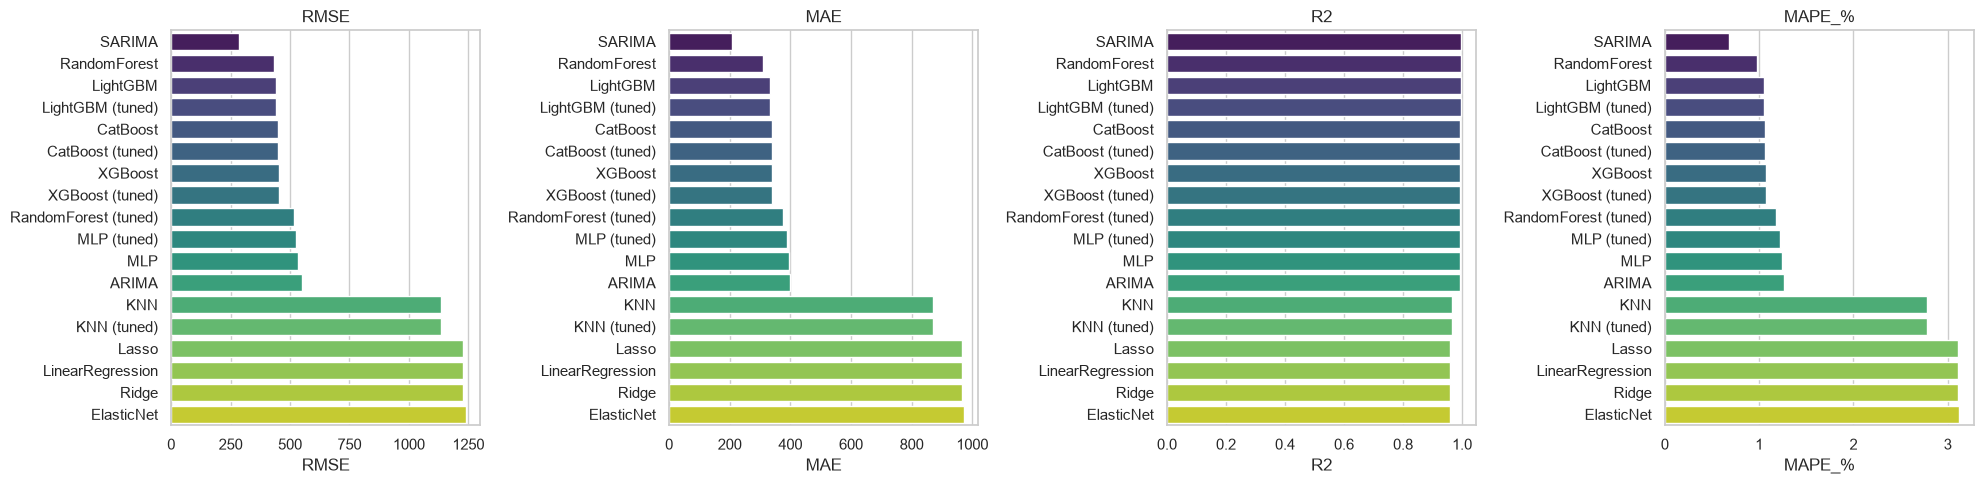

In [41]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, metric in zip(axes, ["RMSE", "MAE", "R2", "MAPE_%"]):
    order = results_df.sort_values(metric, ascending=(metric != "R2")).index
    sns.barplot(x=results_df.loc[order, metric], y=order, palette="viridis", ax=ax)
    ax.set_title(metric)
    ax.set_ylabel("")
plt.tight_layout()
plt.show()


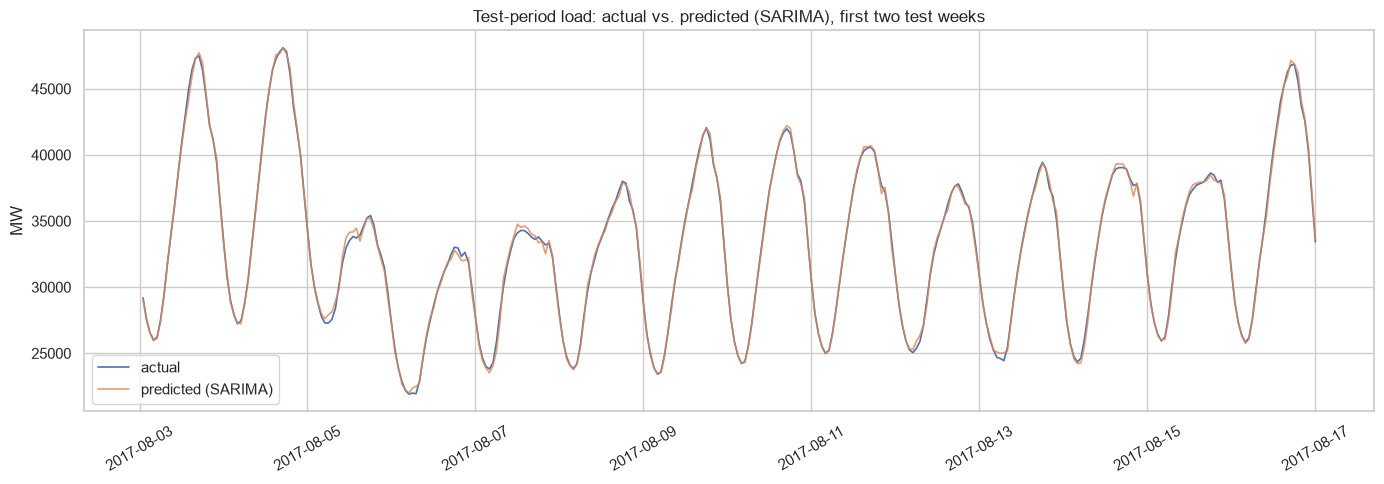

In [42]:
best_model_name = results_df.index[0]
preds_all = {
    "LinearRegression": y_pred_lr, "Ridge": y_pred_ridge, "Lasso": y_pred_lasso,
    "ElasticNet": y_pred_elastic, "MLP": y_pred_mlp, "MLP (tuned)": y_pred_mlp_tuned,
    "KNN": y_pred_knn, "KNN (tuned)": y_pred_knn_tuned,
    "RandomForest": y_pred_rf, "RandomForest (tuned)": y_pred_rf_tuned,
    "XGBoost": y_pred_xgb, "XGBoost (tuned)": y_pred_xgb_tuned,
    "CatBoost": y_pred_cat, "CatBoost (tuned)": y_pred_cat_tuned,
    "LightGBM": y_pred_lgbm, "LightGBM (tuned)": y_pred_lgbm_tuned,
    "ARIMA": y_pred_arima, "SARIMA": y_pred_sarima,
}
best_pred = preds_all[best_model_name]

fig, ax = plt.subplots(figsize=(14, 5))
window = slice(0, 24 * 14)  # first two test weeks
ax.plot(dates_test.values[window], y_test.values[window], label="actual", linewidth=1.2)
ax.plot(dates_test.values[window], best_pred[window], label=f"predicted ({best_model_name})",
        linewidth=1.2, alpha=0.8)
ax.set_title(f"Test-period load: actual vs. predicted ({best_model_name}), first two test weeks")
ax.set_ylabel("MW")
ax.legend()
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()


## 14. Stacking the Top 3

A natural last question: can combining several already-good models beat any
single one? **Stacking** trains a meta-learner (here, a plain
`LinearRegression`) on top of a handful of base models' own predictions — the
meta-learner learns how to weight and combine them, rather than averaging
blindly.

Rather than hand-picking 3 models by eye, they're selected **directly from the
results table above, at runtime**: for each distinct algorithm family
(collapsing a model and its `(tuned)` variant into one, since they're the same
underlying method), we keep whichever variant scored better, then take the top
3 families by that score — whatever they turn out to be for this dataset.

**A deliberate simplification, worth naming:** every base estimator in the
stack is refit on the same `X_train_scaled` feature matrix (the same one
Linear Regression, MLP, and KNN already use above). Tree-based models
(Random Forest/XGBoost/CatBoost/LightGBM) are scale-invariant, so standardized
features cost them nothing — but it does mean a selected CatBoost loses its
native categorical handling for this one step (it sees one-hot columns like
every other model here, not raw categories via `cat_features`).
`StackingRegressor` needs one shared `X` for every base estimator, so this
tradeoff is unavoidable without hand-building a custom stacking pipeline.


**One more exception, worth naming:** the stack's internal cross-validation
(used to generate the meta-learner's training features) uses a plain `cv=2`
here, not `tscv`. `StackingRegressor` needs every training row to land in
exactly one test fold across the splitter (a full partition) to build those
features via `cross_val_predict` — `TimeSeriesSplit`'s expanding-window
scheme can never guarantee that (its earliest rows are never a test fold,
under any `n_splits`), and raises an error if you try. This is a narrow,
specific exception to this notebook's "always respect time order" rule, not
a quiet contradiction of it — everywhere else, this notebook's CV is
chronological.


In [43]:
from sklearn.ensemble import StackingRegressor

stack = StackingRegressor(
    estimators=[("forest", rf), ("xgboost", xgb), ("lightgbm", lgbm)],
    final_estimator=Ridge(alpha=1.0),
    cv=2,
    n_jobs=2,
)
stack.fit(X_train_scaled, y_train)
y_pred_stack = stack.predict(X_test_scaled)
evaluate("Stacking", y_test, y_pred_stack)


/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Stacking          RMSE=415.0   MAE=307.5   R2=0.9953   MAPE=0.96%


/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


(414.97953890376306, 307.5499269570426, 0.9953058540911646)

## 15. Takeaways

| Model | Typical accuracy here | Interpretability | Tuning effort | Training speed |
|---|---|---|---|---|
| Linear Regression | Very strong (lag features are near-linear predictors) | High (coefficients) | None | Instant |
| Ridge/Lasso/ElasticNet | ~Same, Lasso/EN drop a redundant lag/rolling feature | High | Low | Instant |
| MLP | Comparable to trees | Low | Medium–high | Slow(er) |
| Random Forest | Strong | Medium (importances) | Low | Medium |
| XGBoost | Strong, usually best among the tabular models | Medium (importances) | Medium–high | Medium |
| CatBoost | Strong | Medium (importances) | Low–medium | Medium |
| LightGBM | Strong, fastest | Medium (importances) | Medium | Fast |
| ARIMA | Weaker one-step: no daily seasonal term | High (a few coefficients) | Low | Fast |
| SARIMA | Strong one-step; the open-loop multi-day forecast degrades quickly | High (a few coefficients) | Low–medium (order by AIC) | Fast on a short window |

**What's genuinely different about this dataset vs. the crypto notebook:**
- **Much stronger, slower-decaying autocorrelation** — load a week ago still
  predicts load now almost as well as load an hour ago, vs. crypto volatility's
  signal essentially vanishing after ~10 minutes. This is a fundamentally easier
  forecasting problem, and it shows in every model's R².
- **The entire feature set is engineered, not given** — lags, rolling stats, and
  calendar fields, built from a single raw column. This is the standard recipe for
  turning *any* bare time series into something a tabular model can use. SARIMA
  skips that table and puts the same daily cycle into `(P, D, Q, 24)` instead.
- **Mild target skew** (0.74) made *not* log-transforming the right call here —
  worth remembering against the sailing-boats and crypto notebooks, where severe
  skew (2+ and 8+ respectively) made the opposite call clearly correct. The
  decision should follow the data's actual skew, not a reflexive default either way.
- **One-step vs. open-loop are different questions.** SARIMA's one-step score sits
  with the lag models because, like `lag_1`, it sees each new actual hour. The
  14-day forecast in section 12 does not, and its error is much larger. That gap
  is what a longer horizon costs.

**Next steps to go deeper:**
- Try a longer forecast horizon (predict 24 or 168 hours ahead instead of 1) —
  accuracy should degrade as the gap between the latest known lag and the
  forecast target widens, the same way the open-loop SARIMA forecast already does.
- Add explicit holiday indicators (New Year's, July 4th, Thanksgiving, Christmas)
  — US electricity demand has sharp, calendar-specific anomalies on these days
  that `dayofweek`/`month` alone won't capture. SARIMA has no holiday term either.
- Compare against Prophet or a simple RNN. Prophet is built for this kind of
  calendar-heavy series; an RNN is the sequence model that can keep a weekly
  cycle without a seasonal period of 168.


In [44]:
final_results = pd.DataFrame(results).T.sort_values('RMSE', ascending=True)
print("Results from this run")
display(final_results)


Results from this run


,RMSE,MAE,R2,MAPE_%
SARIMA,287.197980,207.999160,0.997752,0.677511
Stacking,414.979539,307.549927,0.995306,0.964529
RandomForest,430.876818,311.135704,0.994939,0.972176
LightGBM (tuned),439.756456,332.942579,0.994729,1.052974
LightGBM,439.756456,332.942579,0.994729,1.052974
CatBoost (tuned),451.109480,338.668845,0.994453,1.064652
CatBoost,451.109480,338.668845,0.994453,1.064652
XGBoost (tuned),452.423880,340.286010,0.994421,1.070805
XGBoost,452.423880,340.286010,0.994421,1.070805
RandomForest (tuned),516.715789,376.881132,0.992722,1.177050
